# 1. Cleaning

In [ ]:
import numpy as np
import pandas as pd


In [2]:
df = pd.read_csv('loan_logreg.csv', encoding = 'utf-8')

In [3]:
pd.set_option('display.max_columns', None)
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303638 entries, 0 to 1303637
Data columns (total 26 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   loan_amnt             1303638 non-null  int64  
 1   is_term_sixty         1303638 non-null  int64  
 2   purpose               1303638 non-null  object 
 3   is_whole_offer        1303638 non-null  int64  
 4   is_joint_application  1303638 non-null  int64  
 5   emp_length            1228181 non-null  float64
 6   home_ownership        1303638 non-null  object 
 7   annual_inc            1303638 non-null  int64  
 8   verification_status   1303638 non-null  object 
 9   verif_status          1303638 non-null  int64  
 10  addr_state            1303638 non-null  object 
 11  delinq_2yrs           1303638 non-null  int64  
 12  inq_last_6mths        1303638 non-null  int64  
 13  pub_rec               1303638 non-null  int64  
 14  pub_rec_bankruptcies  1303638 non-

In [4]:
df = df.drop(columns=['verification_status'])

In [5]:
s = df["emp_length"].value_counts(normalize=True)
missing = df['emp_length'].isnull()
df.loc[missing,'emp_length'] = np.random.choice(s.index, size=len(df[missing]),p=s.values)

In [6]:
df.head(20)

,loan_amnt,is_term_sixty,purpose,is_whole_offer,is_joint_application,emp_length,home_ownership,annual_inc,verif_status,addr_state,delinq_2yrs,inq_last_6mths,pub_rec,pub_rec_bankruptcies,total_acc,mort_acc,dti,open_acc,revol_bal,revol_util,acc_now_delinq,tot_coll_amt,tot_cur_bal,is_default,credit_hist_months
0,30000,0,debt_consolidation,1,1,5.0,MORTGAGE,100000,1,CA,0,0,1,1,19,1,30.46,11,15603,37.0,0,0,472330,0,83
1,40000,1,credit_card,1,1,0.0,MORTGAGE,45000,2,OH,0,0,0,0,37,1,50.53,18,34971,64.5,0,0,271068,0,114
2,20000,0,credit_card,1,1,10.0,MORTGAGE,100000,0,WA,0,0,0,0,19,5,18.92,9,25416,29.9,0,0,515779,0,238
3,4500,0,credit_card,1,0,10.0,RENT,38500,0,TX,0,0,0,0,25,0,4.64,12,4472,15.3,0,306,29137,0,180
4,8425,0,credit_card,1,1,3.0,MORTGAGE,450000,2,MA,0,0,0,0,37,4,12.37,21,36812,65.7,0,0,690320,0,254
5,20000,1,debt_consolidation,1,0,4.0,RENT,57000,0,WA,0,0,0,0,16,1,22.18,10,33356,45.9,0,0,33356,0,284
6,6600,0,credit_card,0,0,10.0,RENT,45000,0,TX,0,0,0,0,13,0,16.21,6,6167,58.2,0,0,26836,0,116
7,2500,0,other,0,0,5.0,RENT,42000,0,PA,0,0,0,0,6,0,15.09,3,3319,31.6,0,0,18649,0,177
8,4000,0,house,1,0,5.0,MORTGAGE,60000,1,TX,0,1,0,0,18,2,19.10,11,382,7.3,0,0,106556,0,138
9,2700,0,credit_card,0,0,4.0,OWN,24000,0,MI,0,0,1,1,28,0,24.95,21,2696,36.4,0,449,75363,0,194


In [6]:
from scipy.stats import mannwhitneyu, chi2_contingency

isdef = df[df["is_default"] == 1]
non = df[df["is_default"] == 0]

In [8]:
print(len(isdef), len(non))

261686 1041952


In [7]:
num_features = ["loan_amnt", "emp_length", "annual_inc", "verif_status", "delinq_2yrs", "inq_last_6mths", "pub_rec", "pub_rec_bankruptcies", "total_acc", "mort_acc", "dti", "open_acc", "revol_bal", "revol_util", "acc_now_delinq", "tot_coll_amt", "tot_cur_bal", "credit_hist_months"]

bin_features = ["is_term_sixty", "is_whole_offer", "is_joint_application"]

cat_features = ["purpose", "home_ownership", "addr_state"]

In [9]:
def rank_biserial(g1, g2, u_stat):
    # effect size for mann-whitney, ranges -1 to 1
    return 1 - (2 * u_stat) / (len(g1) * len(g2))


def cramers_v(chi2_stat, n, shape):
    min_dim = min(shape[0] - 1, shape[1] - 1)
    return np.sqrt(chi2_stat / (n * min_dim))


def run_mwu(features):
    out = []
    for f in features:
        if f not in df.columns:
            continue
        u, p = mannwhitneyu(isdef[f], non[f], alternative="two-sided")
        out.append({
            "feature":   f,
            "isdef_mean": round(isdef[f].mean(), 4),
            "non_mean": round(non[f].mean(), 4),
            "U":         round(u, 1),
            "rank_biserial": round(rank_biserial(isdef[f], non[f], u), 4),
            "p_value":   p,
        })
    return pd.DataFrame(out)


def run_chi2_bin(features):
    n_total = len(df)
    out = []
    for f in features:
        if f not in df.columns:
            continue
        table = pd.crosstab(df["is_default"], df[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":     f,
            "isdef_rate":    round(isdef[f].mean(), 4),   # proportion flagged in isdef
            "non_rate":    round(non[f].mean(), 4),
            "chi2":        round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":     f'{p:.3e}',
        })
    return pd.DataFrame(out)

def run_chi2_cat(features):
    n_total = len(df)
    out = []
    for f in features:
        if f not in df.columns:
            continue
        table = pd.crosstab(df["is_default"], df[f])
        chi2, p, dof, _ = chi2_contingency(table)
        out.append({
            "feature":    f,
            "chi2":       round(chi2, 2),
            "cramers_v":  round(cramers_v(chi2, n_total, table.shape), 4),
            "p_value":    f'{p:.3e}',
            "n_levels":   table.shape[1],
        })
    return pd.DataFrame(out)

In [10]:
pd.reset_option('float_format')
print("=== INDEPENDENT CONTINUOUS FEATURES (Mann-Whitney U) ===")
cont_results = run_mwu(num_features)
cont_sorted = cont_results.sort_values("p_value")
print(cont_sorted.assign(p_value=cont_sorted["p_value"].map(lambda p: f"{p:.3e}"))
      .to_string(index=False), "\n")

print("=== INDEPENDENT BINARY FEATURES (Chi-squared) ===")
bin_results = run_chi2_bin(bin_features)
print(bin_results.sort_values("p_value").to_string(index=False), "\n")

print("=== INDEPENDENT CATEGORICAL FEATURES (Chi-squared) ===")
cat_results = run_chi2_cat(cat_features)
print(cat_results.sort_values("p_value").to_string(index=False), "\n")

=== INDEPENDENT CONTINUOUS FEATURES (Mann-Whitney U) ===
             feature  isdef_mean    non_mean            U  rank_biserial    p_value
           loan_amnt  15549.0091  14132.4937 1.501466e+11        -0.1013  0.000e+00
          revol_util     54.8616     51.1287 1.481982e+11        -0.0870  0.000e+00
                 dti     20.1570     17.7766 1.576540e+11        -0.1564  0.000e+00
            mort_acc      1.3391      1.6856 1.225827e+11         0.1009  0.000e+00
         tot_cur_bal 114054.0719 138723.9445 1.268823e+11         0.0693  0.000e+00
  credit_hist_months    189.0189    196.5421 1.286750e+11         0.0562  0.000e+00
        verif_status      1.1524      0.9766 1.529311e+11        -0.1218  0.000e+00
          annual_inc  70327.2754  77623.3265 1.230506e+11         0.0974  0.000e+00
      inq_last_6mths      0.7813      0.6284 1.476539e+11        -0.0830  0.000e+00
             pub_rec      0.2472      0.2076 1.403898e+11        -0.0298 1.074e-286
            open_ac

In [11]:
# bonferroni correction
n_tests = len(cont_results) + len(bin_results) + len(cat_results)
alpha_adj = 0.05 / n_tests
print(f"tests run: {n_tests}")
print(f"bonferroni-adjusted alpha: {round(alpha_adj, 5)}")
print("(features below this p-value are significant after correction)")

tests run: 24
bonferroni-adjusted alpha: 0.00208
(features below this p-value are significant after correction)


In [14]:
def level_summary(df, f, target="is_default"):
    table = pd.crosstab(df[f], df[target])          # columns: 0, 1
    chi2, p, dof, expected = chi2_contingency(table)
    N = table.values.sum()
    row_tot = table.sum(axis=1).values
    col_tot = table.sum(axis=0).values

    obs_def = table[1].values
    exp_def = expected[:, 1]
    adj_resid = (obs_def - exp_def) / np.sqrt(
        exp_def * (1 - row_tot / N) * (1 - col_tot[1] / N)
    )

    overall = df[target].mean()
    out = pd.DataFrame({
        "n": row_tot,
        "default_rate": obs_def / row_tot,
        "lift": (obs_def / row_tot) / overall,
        "adj_resid": adj_resid,
    }, index=table.index)
    return out.sort_values("default_rate", ascending=False).round(4)


In [16]:
for f in ["purpose", "home_ownership", "addr_state"]:
    display(level_summary(df, f))

,n,default_rate,lift,adj_resid
purpose,,,,
small_business,15010,0.2975,1.4819,29.7594
renewable_energy,911,0.2371,1.1812,2.7413
moving,9173,0.2345,1.1682,8.1003
medical,15024,0.2191,1.0916,5.6574
house,6967,0.2172,1.0819,3.4333
debt_consolidation,757610,0.2126,1.0590,39.7942
other,74937,0.2117,1.0548,7.7454
vacation,8732,0.1924,0.9585,-1.9521
major_purchase,28328,0.1872,0.9327,-5.7353


,n,default_rate,lift,adj_resid
home_ownership,,,,
RENT,517821,0.2335,1.1632,75.8057
OWN,139849,0.2075,1.0336,6.6657
ANY,267,0.1948,0.9702,-0.2439
OTHER,144,0.1875,0.9341,-0.3965
MORTGAGE,645509,0.1730,0.8618,-78.2890
NONE,48,0.1458,0.7265,-0.9496


,n,default_rate,lift,adj_resid
addr_state,,,,
MS,6316,0.2620,1.3054,12.1917
NE,3422,0.2542,1.2665,7.8239
AR,9708,0.2417,1.2039,10.1037
AL,16130,0.2374,1.1826,11.6929
OK,11846,0.2371,1.1813,9.9336
LA,15021,0.2341,1.1661,10.2598
NY,106387,0.2215,1.1033,17.6224
NV,19652,0.2205,1.0986,6.9832
IN,21020,0.2161,1.0767,5.6169


# 2. EDA

<Axes: >

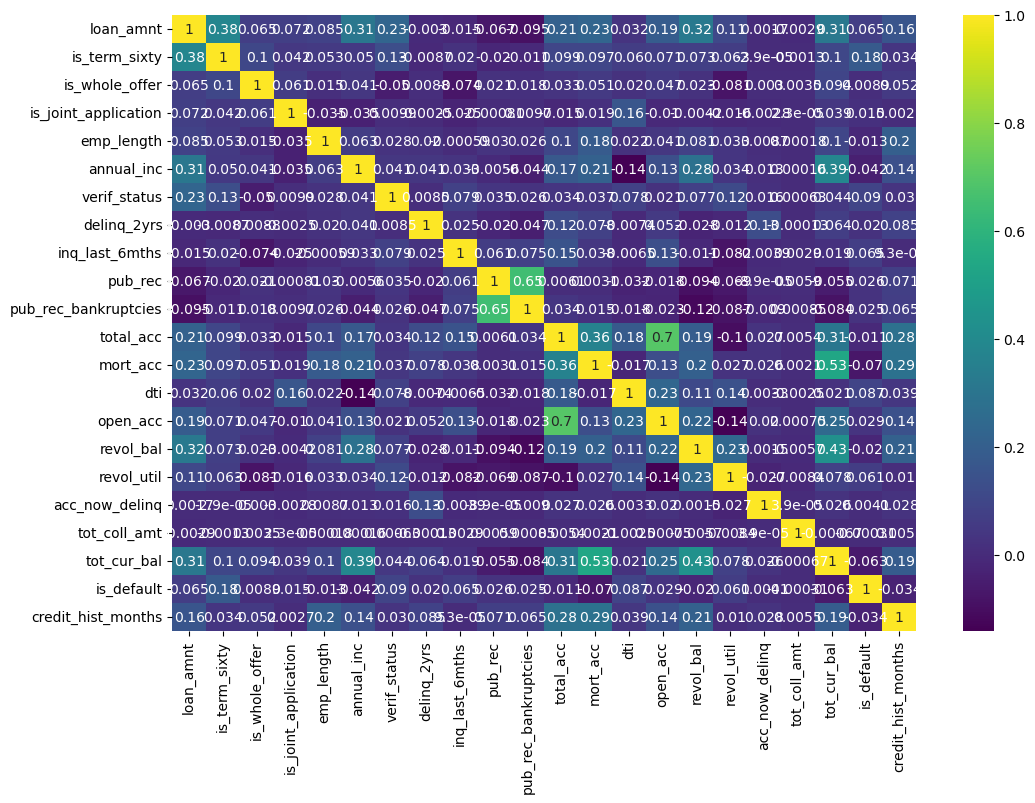

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,8))
sns.heatmap(df.loc[:, [col for col in df.columns if col not in cat_features]].corr(), annot=True, cmap='viridis')

# 3. Modelling

In [8]:
counts = df['addr_state'].value_counts()
idx = counts[counts.lt(5000)].index

df.loc[df['addr_state'].isin(idx), 'addr_state'] = 'Others'


In [9]:
df['addr_state'].value_counts()

addr_state
CA        191036
TX        106677
NY        106387
FL         92620
IL         50030
NJ         46885
PA         44117
OH         42438
GA         42032
VA         36852
NC         36615
Others     35068
MI         34128
AZ         31716
MD         30224
MA         30007
CO         28859
WA         28362
MN         23242
IN         21020
MO         20563
TN         19667
NV         19652
CT         19063
WI         17138
AL         16130
OR         15965
SC         15477
LA         15021
KY         12439
OK         11846
KS         10892
UT          9785
AR          9708
NM          7158
HI          6568
MS          6316
NH          6243
RI          5692
Name: count, dtype: int64

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303638 entries, 0 to 1303637
Data columns (total 25 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   loan_amnt             1303638 non-null  int64  
 1   is_term_sixty         1303638 non-null  int64  
 2   purpose               1303638 non-null  object 
 3   is_whole_offer        1303638 non-null  int64  
 4   is_joint_application  1303638 non-null  int64  
 5   emp_length            1303638 non-null  float64
 6   home_ownership        1303638 non-null  object 
 7   annual_inc            1303638 non-null  int64  
 8   verif_status          1303638 non-null  int64  
 9   addr_state            1303638 non-null  object 
 10  delinq_2yrs           1303638 non-null  int64  
 11  inq_last_6mths        1303638 non-null  int64  
 12  pub_rec               1303638 non-null  int64  
 13  pub_rec_bankruptcies  1303638 non-null  int64  
 14  total_acc             1303638 non-

In [ ]:

from sklearn.preprocessing import OneHotEncoder

categorical_columns = df.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False)

encoded_data = encoder.fit_transform(df[categorical_columns])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns)
)

df1 = pd.concat(
    [df.drop(columns=categorical_columns), encoded_df],
    axis=1
)

In [ ]:
# sampling to drastically reduce
df2 = df1.sample(n=50000, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

x = df2.drop(columns=['is_default'])
y = df2['is_default']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y, random_state=42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled  = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x.columns, index=x_train.index)
x_test_scaled  = pd.DataFrame(x_test_scaled,  columns=x.columns, index=x_test.index)

In [14]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\n[A] scale_pos_weight = {spw:.3f}")

from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_scaled, y_train)
print(f"[B] after SMOTE -> train: {x_train_smote.shape[0]}, pos rate: {y_train_smote.mean():.3f}")


[A] scale_pos_weight = 3.943
[B] after SMOTE -> train: 63814, pos rate: 0.500


In [22]:
from xgboost import XGBClassifier
# hyperparameter tuning ~20 minutes runtime for 2500 fits

param_grid = {
    'n_estimators': [200, 300],
    'max_depth': [3, 5, 7],             # very important
    'min_child_weight': [3, 5, 7],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'learning_rate': [0.01, 0.1, 0.3]   # very important
}

# Create XGBoost classifier
xgb = XGBClassifier(random_state=42) # default values

# Perform grid search
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=5, n_jobs=-1, verbose=5, scoring='roc_auc')
grid_search.fit(x_train, y_train)

# print best parameters
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best score: {grid_search.best_score_}")

Fitting 5 folds for each of 486 candidates, totalling 2430 fits
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 3, 'n_estimators': 200, 'subsample': 0.8}
Best score: 0.690819115117303


In [ ]:
parameters = dict(
    n_estimators=200,
    max_depth=5,
    min_child_weight=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

model_a = XGBClassifier(scale_pos_weight=spw, **parameters)
model_a.fit(x_train_scaled, y_train)

model_b = XGBClassifier(scale_pos_weight=1, **parameters)
model_b.fit(x_train_smote, y_train_smote)

# metrics
from sklearn.metrics import roc_auc_score, f1_score

for name, model in [("A (scale_pos_weight)", model_a), ("B (SMOTE)", model_b)]:
    proba = model.predict_proba(x_test_scaled)[:, 1]
    pred  = model.predict(x_test_scaled)
    auc   = roc_auc_score(y_test, proba)
    f1    = f1_score(y_test, pred)
    print(f"  {name}: AUC={auc:.4f}, F1={f1:.4f}")


  A (scale_pos_weight): AUC=0.6949, F1=0.4216
  B (SMOTE): AUC=0.6837, F1=0.1903


In [32]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = model_a

#predictions on the untouched test set
y_pred  = model.predict(x_test_scaled)
y_proba = model.predict_proba(x_test_scaled)[:, 1]

In [41]:
print(classification_report(y_test, y_pred, target_names=["non_default", "default"], digits=4))

              precision    recall  f1-score   support

 non_default     0.8699    0.6909    0.7701      7977
     default     0.3271    0.5927    0.4216      2023

    accuracy                         0.6710     10000
   macro avg     0.5985    0.6418    0.5959     10000
weighted avg     0.7601    0.6710    0.6996     10000



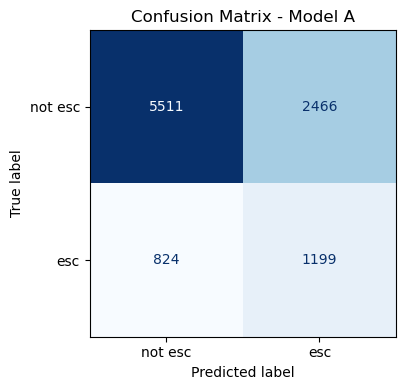

In [36]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["not esc", "esc"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Model A")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [45]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test_scaled)
tp_mask = (y_test.values == 1) & (y_pred == 1)
tp_idx  = np.where(tp_mask)[0][0] 

print(f"\nwaterfall for test row {tp_idx} (true positive)")
plt.figure()
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[tp_idx],
        base_values=explainer.expected_value,
        data=x_test_scaled.iloc[tp_idx],
        feature_names=list(x_test_scaled.columns),
    ),
    show=False,
)
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

ImportError: 

IMPORTANT: PLEASE READ THIS FOR ADVICE ON HOW TO SOLVE THIS ISSUE!

Importing the numpy C-extensions failed. This error can happen for
many reasons, often due to issues with your setup or how NumPy was
installed.

We have compiled some common reasons and troubleshooting tips at:

    https://numpy.org/devdocs/user/troubleshooting-importerror.html

Please note and check the following:

  * The Python version is: Python3.12 from "d:\anaconda\python.exe"
  * The NumPy version is: "1.26.4"

and make sure that they are the versions you expect.
Please carefully study the documentation linked above for further help.

Original error was: DLL load failed while importing _multiarray_umath: Не найден указанный модуль.


ImportError: numpy._core.multiarray failed to import